In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

In [5]:
df = pd.read_csv("/content/Life Expectancy Data.csv", encoding='latin1', sep=None, engine='python')

In [6]:
df.columns = df.columns.str.strip().str.replace(r'\s+', ' ', regex=True)

In [7]:
numeric_cols = [
    'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol',
    'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI',
    'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria',
    'HIV/AIDS', 'GDP', 'Population', 'thinness 1-19 years',
    'thinness 5-9 years', 'Income composition of resources', 'Schooling'
]

In [8]:
for col in numeric_cols:
    if col in df.columns:
        if df[col].dtype == 'object':
            df[col] = df[col].astype(str).str.replace(',', '', regex=False).str.strip()
        df[col] = pd.to_numeric(df[col], errors='coerce')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [10]:
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [11]:
missing_data = pd.DataFrame({
    'MISSING_COUNT': df.isnull().sum(),
    'MISSING_PERCENTAGE (%)': (df.isnull().sum() / len(df)) * 100
})
print("--- MISSING VALUE REPORT ---")
print(missing_data[missing_data['MISSING_COUNT'] > 0].sort_values(by='MISSING_COUNT', ascending=False))
print("\n")
df = df.dropna(subset=['Life expectancy'])

--- MISSING VALUE REPORT ---
                                 MISSING_COUNT  MISSING_PERCENTAGE (%)
Population                                 652               22.191967
Hepatitis B                                553               18.822328
GDP                                        448               15.248468
Total expenditure                          226                7.692308
Alcohol                                    194                6.603131
Income composition of resources            167                5.684139
Schooling                                  163                5.547992
thinness 5-9 years                          34                1.157250
thinness 1-19 years                         34                1.157250
BMI                                         34                1.157250
Polio                                       19                0.646698
Diphtheria                                  19                0.646698
Life expectancy                             10  

In [12]:
df['Health_GDP_Ratio'] = df['Total expenditure'] / (df['GDP'] + 1)
df['Avg_Thinness'] = (df['thinness 1-19 years'] + df['thinness 5-9 years']) / 2
df['Immunity_Index'] = (df['Hepatitis B'].fillna(0) + df['Polio'].fillna(0) + df['Diphtheria'].fillna(0)) / 3
df['Dev_Index'] = df['Income composition of resources'] * df['Schooling']

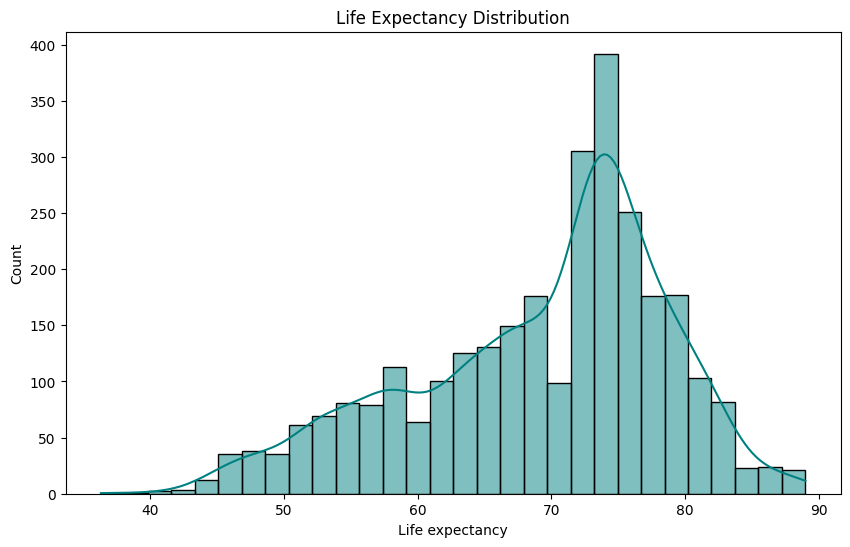

In [13]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Life expectancy'], kde=True, color='teal')
plt.title("Life Expectancy Distribution")
plt.savefig("target_distribution.png")
plt.show()

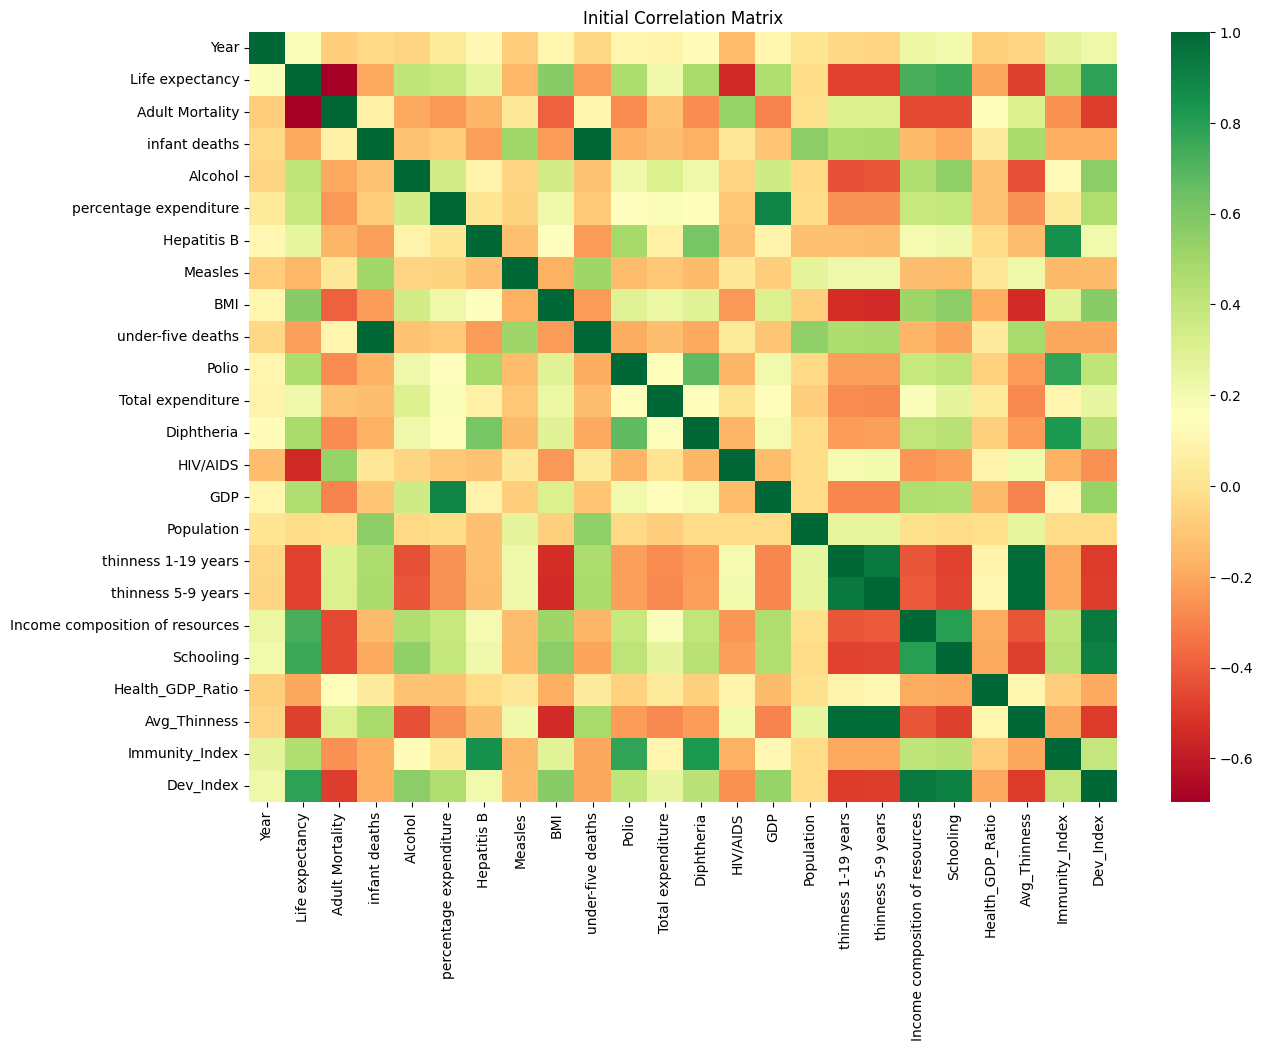

In [14]:
plt.figure(figsize=(14, 10))
initial_corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(initial_corr, annot=False, cmap='RdYlGn')
plt.title("Initial Correlation Matrix")
plt.savefig("initial_corr.png")
plt.show()

In [15]:
target_corr = initial_corr['Life expectancy'].sort_values(ascending=False)
print("--- CORRELATIONS OF TARGETED VARIBLES ---")
print(target_corr.head(8))
print("\n")

--- CORRELATIONS OF TARGETED VARIBLES ---
Life expectancy                    1.000000
Dev_Index                          0.786250
Schooling                          0.751975
Income composition of resources    0.724776
BMI                                0.567694
Diphtheria                         0.479495
Polio                              0.465556
GDP                                0.461455
Name: Life expectancy, dtype: float64




In [16]:
num_cols_to_fill = df.select_dtypes(include=[np.number]).columns
df[num_cols_to_fill] = df.groupby('Country')[num_cols_to_fill].transform(lambda x: x.fillna(x.mean()))
df[num_cols_to_fill] = df[num_cols_to_fill].fillna(df[num_cols_to_fill].median())

In [17]:
X = df.drop(['Life expectancy', 'Country'], axis=1)
X = pd.get_dummies(X, columns=['Status'], drop_first=True)
y = df['Life expectancy']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [19]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, None],
    'min_samples_split': [2, 5]
}

In [20]:
rf = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, n_jobs=-1, scoring='r2')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

In [21]:
y_pred = best_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

In [22]:
print("--- MODEL OUTCOMES ---")
print(f"En İyi Parametreler: {grid_search.best_params_}")
print(f"R-Kare (R2): {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}\n")

--- MODEL OUTCOMES ---
En İyi Parametreler: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
R-Kare (R2): 0.9679
MAE: 1.0498
RMSE: 1.6669



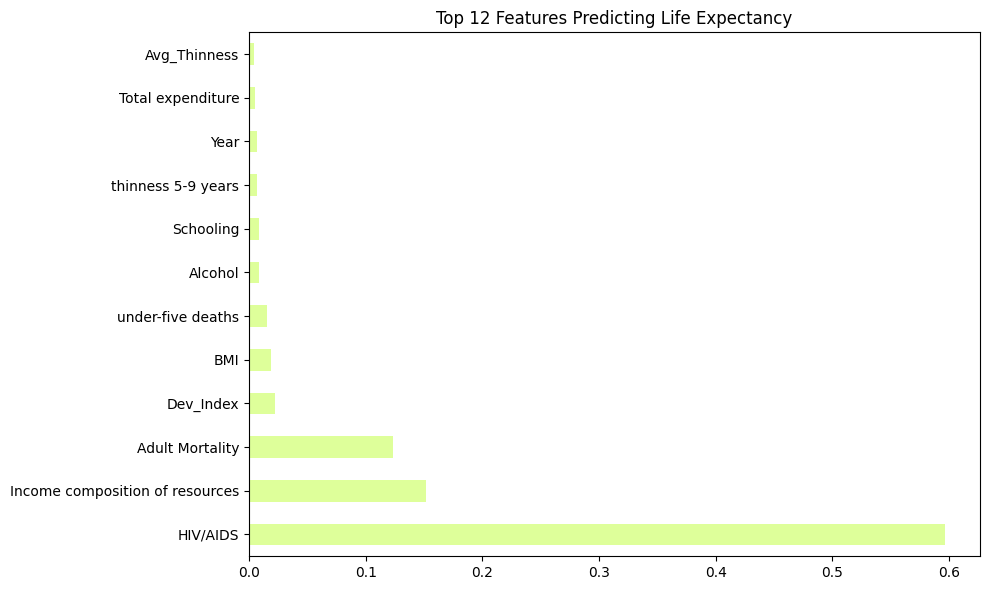

In [23]:
plt.figure(figsize=(10, 6))
feat_importances = pd.Series(best_model.feature_importances_, index=X.columns)
feat_importances.nlargest(12).plot(kind='barh', color='#deff9a')
plt.title('Top 12 Features Predicting Life Expectancy')
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

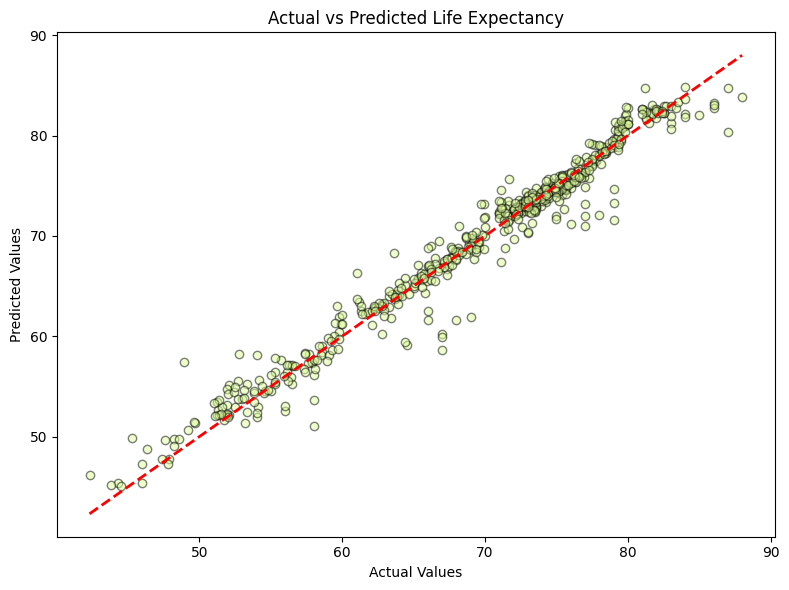

In [24]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='#deff9a', edgecolors='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Life Expectancy')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.tight_layout()
plt.savefig("actual_vs_predicted.png")
plt.show()

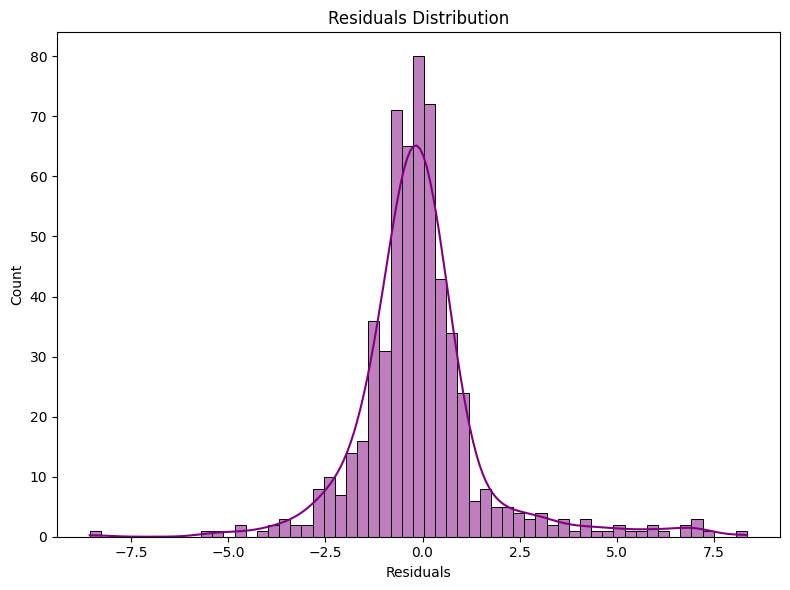

In [25]:
plt.figure(figsize=(8, 6))
residuals = y_test - y_pred
sns.histplot(residuals, kde=True, color='purple')
plt.title('Residuals Distribution')
plt.xlabel('Residuals')
plt.tight_layout()
plt.savefig("residuals_distribution.png")
plt.show()

In [26]:
!pip install wandb -q
import wandb
wandb.login()

run = wandb.init(entity="ml-group-j",
                 project="life-expectancy-ml",
                 name="random-forest",
                 config=grid_search.best_params_)
wandb.log({"test_R2": r2, "test_MAE": mae, "test_RMSE": rmse})
wandb.finish()

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gulhayourinova97 (ml-group-j) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


test_MAE,▁
test_R2,▁
test_RMSE,▁
test_MAE,1.0498
test_R2,0.96788
test_RMSE,1.66687
